# 🧹 Nettoyage de Texte et Nuages de Mots (NLP Classique)

Bienvenue dans le monde du Traitement du Langage Naturel (NLP) !
Avant de demander à une intelligence artificielle de lire des milliers d'avis, il est indispensable de préparer le texte. Un texte brut contient beaucoup de "bruit" : des majuscules, de la ponctuation, et des mots vides (comme "le", "la", "de", "et") qui n'apportent aucune information sur le sentiment.

Nous allons utiliser **NLTK (Natural Language Toolkit)**, la bibliothèque de référence, pour nettoyer tout ça.

In [1]:
import pandas as pd
import re
import nltk
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Téléchargement des outils linguistiques de NLTK
nltk.download('stopwords') # La liste des "mots vides"
nltk.download('punkt_tab') # L'outil pour découper les phrases en mots (Tokenization)

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jovyb\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jovyb\AppData\Roaming\nltk_data...


[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


## 1. Découverte des données

In [2]:
# Chargement des faux avis e-commerce générés
df = pd.read_csv('../data/avis_clients.csv')
display(df.head())
print("\nRépartition des sentiments dans notre dataset :")
print(df['Sentiment_Reel'].value_counts())

,Texte,Sentiment_Reel,Note
0,"Je demande un remboursement, la qualité est mé...",Negatif,2
1,"Parfait, rien à redire. Fonctionne comme prévu.",Positif,4
2,"Le service client est catastrophique, impossib...",Negatif,1
3,Livraison très rapide et article conforme à la...,Positif,4
4,"La batterie ne tient pas du tout, c'est de l'a...",Negatif,1



Répartition des sentiments dans notre dataset :
Sentiment_Reel
Positif    300
Negatif    250
Neutre     150
Name: count, dtype: int64


## 2. Le Pipeline de Nettoyage (Text Preprocessing)

Nous allons créer une fonction qui effectue 4 étapes fondamentales :
1. **Minuscules** : Transformer "Génial" et "génial" en un seul mot.
2. **Ponctuation** : Supprimer les virgules, points d'exclamation, etc.
3. **Tokenization** : Découper la phrase en une liste de mots `['livraison', 'très', 'rapide']`.
4. **Stopwords** : Retirer les mots inutiles en français.

In [3]:
# Chargement des mots vides en français
stop_words_francais = set(stopwords.words('french'))

# Ajout de quelques mots spécifiques au e-commerce qui ne sont pas des sentiments
stop_words_francais.update(['très', 'plus', 'ça', 'comme', 'produit', 'article', 'achat'])

def nettoyer_texte(texte):
    # 1. Tout en minuscules
    texte = texte.lower()
    # 2. Retirer la ponctuation et les nombres (ne garder que les lettres)
    texte = re.sub(r'[^a-zà-ÿ\s]', '', texte)
    # 3. Tokenization (découpage en mots)
    mots = word_tokenize(texte, language='french')
    # 4. Garder uniquement les mots qui ne sont pas dans la liste des stopwords
    mots_propres = [mot for mot in mots if mot not in stop_words_francais]
    
    # On recolle les mots avec des espaces
    return ' '.join(mots_propres)

# On applique notre fonction magique à toute la colonne 'Texte'
df['Texte_Nettoye'] = df['Texte'].apply(nettoyer_texte)

# Comparons avant / après !
display(df[['Texte', 'Texte_Nettoye']].head())

,Texte,Texte_Nettoye
0,"Je demande un remboursement, la qualité est mé...",demande remboursement qualité médiocre
1,"Parfait, rien à redire. Fonctionne comme prévu.",parfait rien redire fonctionne prévu
2,"Le service client est catastrophique, impossib...",service client catastrophique impossible joindre
3,Livraison très rapide et article conforme à la...,livraison rapide conforme description
4,"La batterie ne tient pas du tout, c'est de l'a...",batterie tient tout cest larnaque


Voyez comme le texte est maintenant épuré ! L'ordinateur n'a plus que les mots clés importants à analyser.

## 3. Visualisation : Nuages de mots (WordClouds)

Maintenant que notre texte est propre, essayons de comprendre visuellement ce qui rend nos clients heureux ou mécontents. 
Le WordCloud affiche les mots d'autant plus gros qu'ils reviennent souvent.

C:\Users\jovyb\.gemini\antigravity\scratch\sentiment_analysis\venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


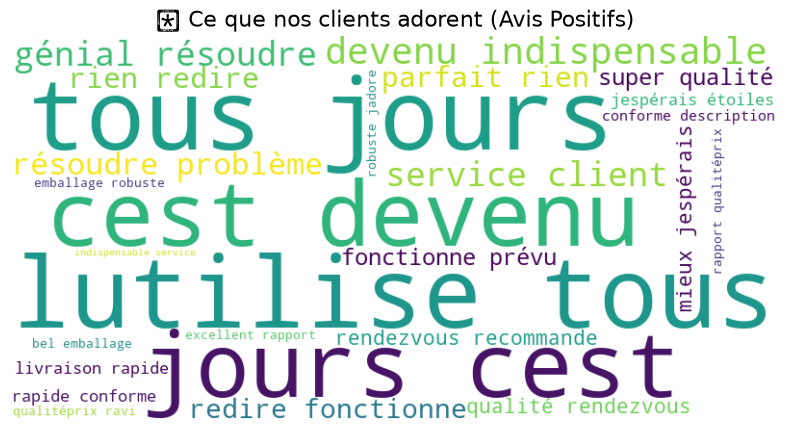

C:\Users\jovyb\.gemini\antigravity\scratch\sentiment_analysis\venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


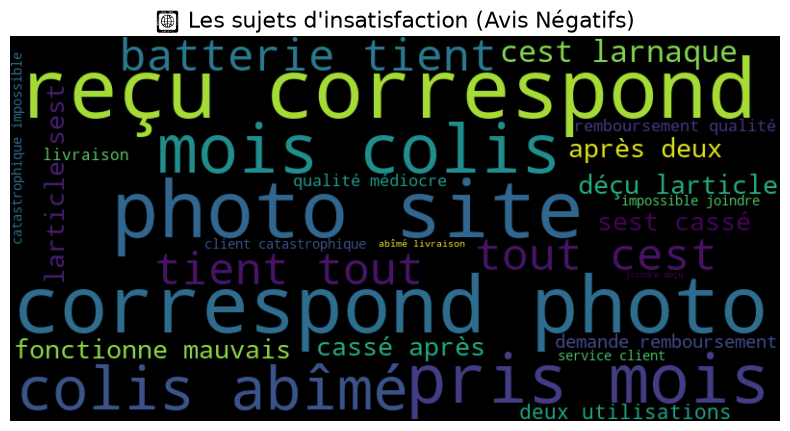

In [4]:
# On sépare les avis positifs et négatifs
textes_positifs = ' '.join(df[df['Sentiment_Reel'] == 'Positif']['Texte_Nettoye'])
textes_negatifs = ' '.join(df[df['Sentiment_Reel'] == 'Negatif']['Texte_Nettoye'])

def afficher_wordcloud(texte, titre, couleur_fond):
    wordcloud = WordCloud(width=800, height=400, background_color=couleur_fond, colormap='viridis').generate(texte)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(titre, fontsize=16)
    plt.axis('off')
    plt.show()

# Affichage
afficher_wordcloud(textes_positifs, "🟢 Ce que nos clients adorent (Avis Positifs)", 'white')
afficher_wordcloud(textes_negatifs, "🔴 Les sujets d'insatisfaction (Avis Négatifs)", 'black')

**Analyse Business :**
- Sur le graphique **Positif**, on voit souvent revenir des mots comme "qualité", "rapide", "parfait". Le service client et la livraison rapide sont nos points forts.
- Sur le graphique **Négatif**, des mots comme "cassé", "service client", "retard" ressortent. Il y a visiblement un problème avec les transporteurs ou la solidité des emballages !

---
🎯 **Conclusion de l'étape 1** : Sans même utiliser de Machine Learning complexe, nous avons déjà réussi à extraire les "Pain points" (sujets d'insatisfaction) de notre entreprise rien qu'en comptant intelligemment les mots !